Simulation took 0.02241826057434082 seconds


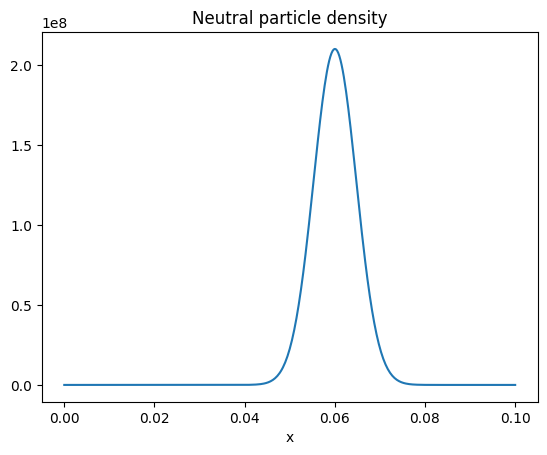

0.05


In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

# Length of the domain
Lx = 0.1
Ly = 0.1
Lz = 0.1


# Number of cells in each direction
nx = 401
ny = 1
nz = 1

# Background parameters
ncells = nx * ny * nz

diffusion_coeff = np.zeros(ncells, dtype=np.float64)
diffusion_coeff.fill(1.0e-4)

advection_coeff_x = np.zeros(ncells, dtype=np.float64)
advection_coeff_x.fill(0.1)
advection_coeff_y = np.zeros(ncells, dtype=np.float64)
advection_coeff_z = np.zeros(ncells, dtype=np.float64)

density = np.zeros(ncells, dtype=np.float64)
density[200] = 1.0e10

t_final = 1.0e-3
dt = 1.0e-6

# Translate parameters into json format

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

config["diffusion"] = diffusion_coeff.tolist()
config["advection_x"] = advection_coeff_x.tolist()
config["advection_y"] = advection_coeff_y.tolist()
config["advection_z"] = advection_coeff_z.tolist()
config["density"] = density.tolist()
config["t_final"] = t_final
config["dt"] = dt

# Run the simulation
inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-fv"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

neutral_density = np.array(output["density"])

x = np.linspace(0,Lx,nx)

plt.plot(x, neutral_density)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.show()
